# 07 — Inference-resolution ablation (960 / 1152 / 1280 px)

**Read-only experiment.** No model was retrained, no checkpoint or dataset file
was modified. Everything in this notebook loads already-computed CSVs/images from
`reports/resolution_ablation/` (produced by the scripts referenced in each
section) -- re-running any cell below only re-reads those files.

## Objective
The P0 diagnostics (`reports/p0_diagnostics/`) found a real, size-correlated
detection gap that affects every class, not just rare ones (e.g. `car` AR on
small instances was only ~34% vs ~87% on large ones at the models' current
validation imgsz). This notebook asks: **does simply evaluating the existing
checkpoints at a higher input resolution recover some of that gap, without any
retraining?**

## Method
- Checkpoints: the same three from every previous round -- `Baseline`,
  `Oversampling`, `Fine-tuning` (`runs/detect/runs/bdd100k_yolo11n_*/weights/best.pt`).
- Resolutions tested: **960, 1152, 1280 px** (BDD100K's native resolution is
  1280x720), same validation split, same `data.yaml`, same NMS `iou=0.70`.
- `conf`: default Ultralytics val threshold (0.001), i.e. the same convention as
  every earlier metrics table in this project.
- `batch=1` for every run, as requested, with inference time and peak GPU memory
  recorded per run, and a `try/except` around CUDA OOM (recorded as a failed row,
  `torch.cuda.empty_cache()`, sweep continues) -- see
  `scripts/run_resolution_ablation.py`.
- All 3 x 3 = 9 runs completed with `status=ok`; **no OOM occurred** on this GPU
  (RTX 2050, 4GB) at batch=1, even at 1280px (peak ~147MB).

In [1]:
import pandas as pd

from pathlib import Path

from IPython.display import Image, display



RA = Path('../reports/resolution_ablation')

global_df = pd.read_csv(RA / 'validation' / 'summary_global_metrics.csv')

per_class_df = pd.read_csv(RA / 'validation' / 'summary_per_class_ap.csv')

size_df = pd.read_csv(RA / 'size_breakdown' / 'size_breakdown_by_class.csv')

print(global_df.shape, per_class_df.shape, size_df.shape)

(9, 16) (81, 7) (45, 14)

## 1. Global metrics vs resolution

`status` is `ok` for all 9 runs (no OOM/errors). Note all three models rise
960→1152 and then fall 1152→1280 on mAP50 and mAP50-95 -- **not a monotonic
"more resolution = better" relationship.**

In [1]:
cols = ['model','imgsz','status','precision','recall','map50','map50_95',

        'speed_inference_ms','peak_gpu_mem_mb']

display(global_df[cols].round(4).sort_values(['model','imgsz']).to_string(index=False))

       model  imgsz status  precision  recall  map50  map50_95  speed_inference_ms  peak_gpu_mem_mb
    baseline    960     ok     0.5377  0.4327 0.4534    0.2439             19.1977          93.5098
    baseline   1152     ok     0.5607  0.4368 0.4560    0.2441             18.9147         130.1226
    baseline   1280     ok     0.5274  0.4168 0.4374    0.2325             18.4926         146.5601
    finetune    960     ok     0.5433  0.4098 0.4255    0.2258             18.6108         104.5444
    finetune   1152     ok     0.5180  0.4249 0.4415    0.2323             18.4672         129.3726
    finetune   1280     ok     0.5299  0.4038 0.4299    0.2278             18.6600         146.5601
oversampling    960     ok     0.5415  0.4458 0.4594    0.2486             18.5127         104.5444
oversampling   1152     ok     0.5852  0.4318 0.4710    0.2502             19.4450         129.3726
oversampling   1280     ok     0.5515  0.4209 0.4578    0.2382             18.3187         146.5601

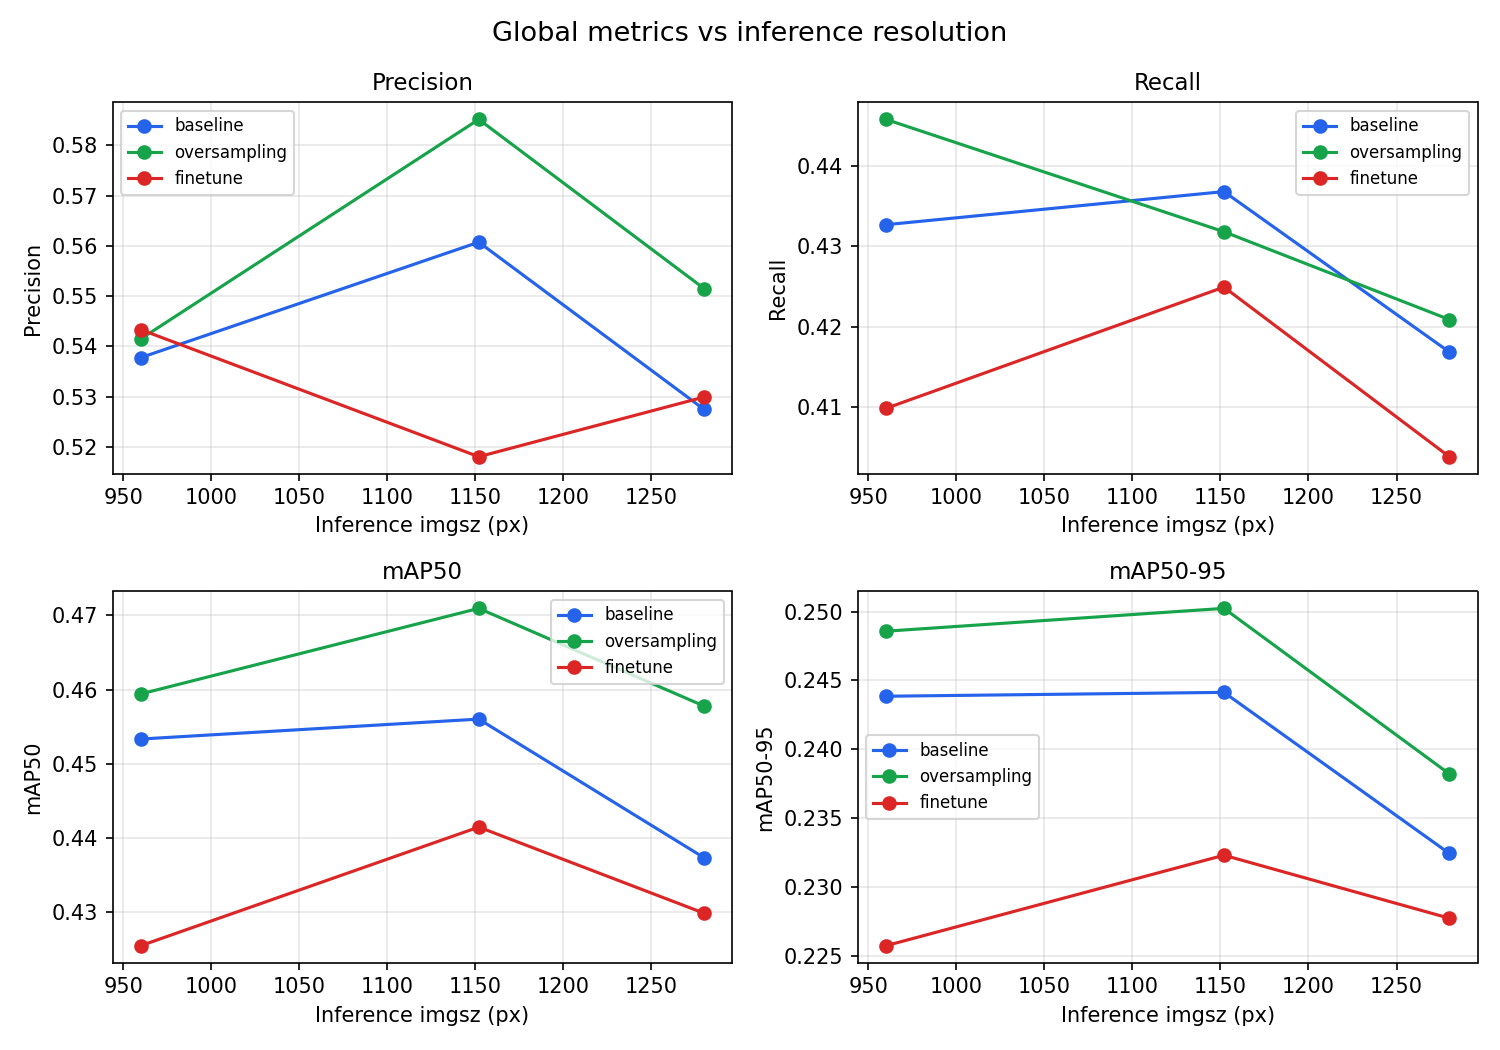

In [1]:
display(Image(filename=str(RA / 'charts' / 'global_metrics_vs_imgsz.png')))

**Reading this chart**: 1152px is a peak for every model on mAP50/mAP50-95
(and for precision on baseline/oversampling). The most likely explanation: the
underlying checkpoints were *trained* at 640px (baseline/oversampling) or 960px
(finetune) -- evaluating far above the training resolution (1280 vs a 640
training size) starts to look like a train/eval domain shift (object-scale
statistics the model never saw during training), which erodes some of the gain
that moving off the training resolution initially provided. This matches
Ultralytics-documented behavior that performance degrades the further
inference resolution strays from training resolution, in *either* direction.

## 2. Per-class AP50 vs resolution

In [1]:
piv = per_class_df.pivot_table(index='class', columns=['model','imgsz'], values='ap50').round(3)

display(piv)

model         baseline               finetune               oversampling              
imgsz             960    1152   1280     960    1152   1280         960    1152   1280
class                                                                                 
bicycle          0.271  0.231  0.203    0.211  0.224  0.201        0.264  0.307  0.299
bus              0.481  0.477  0.453    0.456  0.417  0.408        0.477  0.453  0.446
car              0.748  0.765  0.765    0.725  0.746  0.751        0.748  0.764  0.767
motorcycle       0.200  0.195  0.208    0.183  0.181  0.169        0.337  0.269  0.274
pedestrian       0.557  0.577  0.571    0.538  0.560  0.567        0.560  0.589  0.559
rider            0.347  0.313  0.243    0.271  0.310  0.264        0.262  0.338  0.285
traffic light    0.511  0.537  0.512    0.511  0.551  0.540        0.528  0.542  0.529
traffic sign     0.529  0.552  0.551    0.521  0.553  0.553        0.538  0.558  0.546
truck            0.436  0.458  0.431    0.4

Vulnerable-road-user classes (`rider`, `bicycle`, `motorcycle`) all improve from
960→1152 across every model variant; `rider` and `motorcycle` then give some of
it back at 1280, while `bicycle` keeps improving for oversampling/finetune.

## 3. Inference time and GPU memory (batch=1)

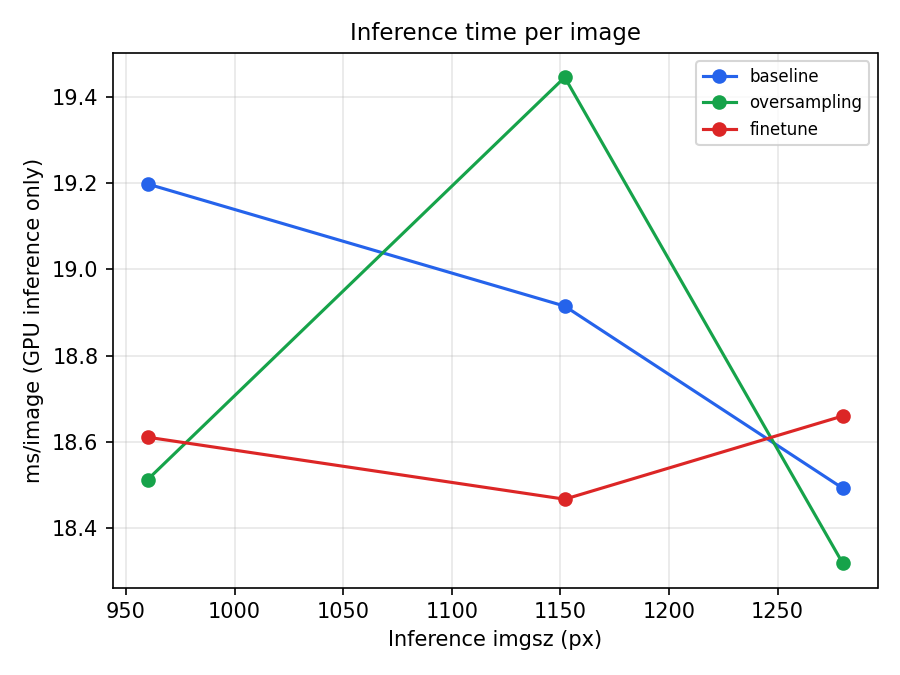

In [1]:
display(Image(filename=str(RA / 'charts' / 'inference_time_vs_imgsz.png')))

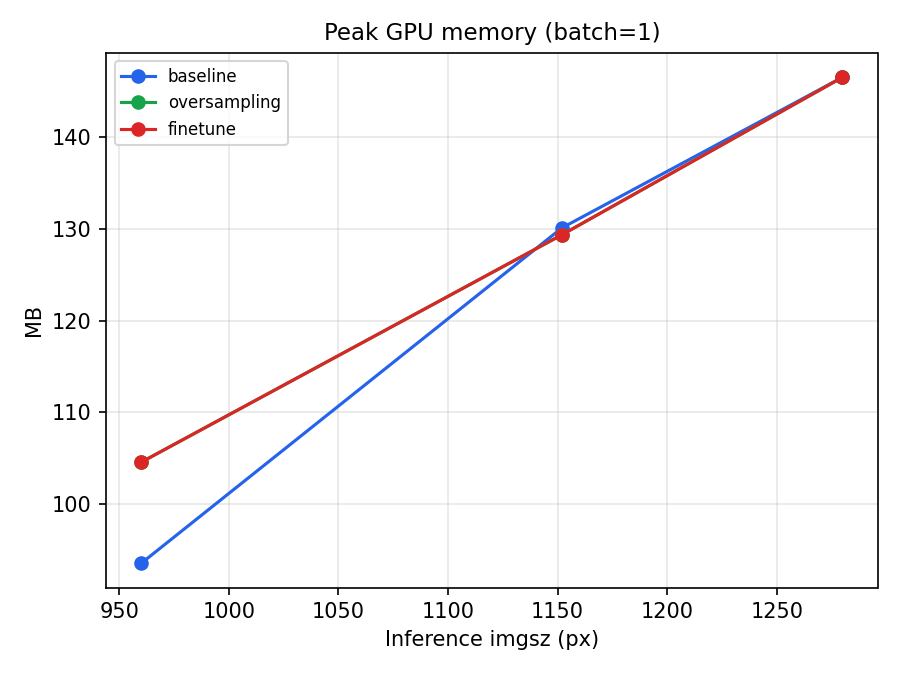

In [1]:
display(Image(filename=str(RA / 'charts' / 'gpu_memory_vs_imgsz.png')))

**Inference time is essentially flat** (~18.3-19.4 ms/image) across 960/1152/1280
at batch=1 -- for a 2.6M-parameter nano model on this GPU, fixed per-call Python/
CUDA-launch overhead dominates, not the resolution-dependent compute. This means
going from 960 to 1152px is **free** in latency terms on this hardware.

**GPU memory does scale with resolution** (~94-105MB @960 → ~130MB @1152 → ~147MB
@1280), but all three stay far under the 4GB budget at batch=1 -- no OOM risk at
any of the tested resolutions on this GPU.

## 4. COCO AR by object size (small < 32²px, medium 32²-96²px, large > 96²px)

Built via `scripts/coco_size_analysis.py` (`faster_coco_eval`) against a GT json
constructed from the YOLO val labels (original-resolution pixel boxes, so this is
comparable across all three `imgsz` values).

In [1]:
vru = size_df[size_df['class'].isin(['pedestrian','rider','motorcycle','bicycle','car'])].copy()

vru[['model_name','imgsz']] = vru['model'].str.extract(r'(\w+)_(\d+)$')

piv = vru.pivot_table(index=['class','model_name'], columns='imgsz',

                       values=['AR_small','gt_small'])

display(piv.round(3))

                        AR_small               gt_small                
imgsz                       1152   1280    960     1152    1280     960
class      model_name                                                  
bicycle    baseline        0.172  0.200  0.117     18.0    18.0    18.0
           finetune        0.106  0.150  0.033     18.0    18.0    18.0
           oversampling    0.217  0.244  0.128     18.0    18.0    18.0
car        baseline        0.373  0.380  0.342   3410.0  3410.0  3410.0
           finetune        0.355  0.372  0.313   3410.0  3410.0  3410.0
           oversampling    0.375  0.381  0.341   3410.0  3410.0  3410.0
motorcycle baseline        0.233  0.193  0.133     15.0    15.0    15.0
           finetune        0.147  0.153  0.040     15.0    15.0    15.0
           oversampling    0.247  0.180  0.207     15.0    15.0    15.0
pedestrian baseline        0.333  0.350  0.299    495.0   495.0   495.0
           finetune        0.307  0.331  0.276    495.0   495.0 

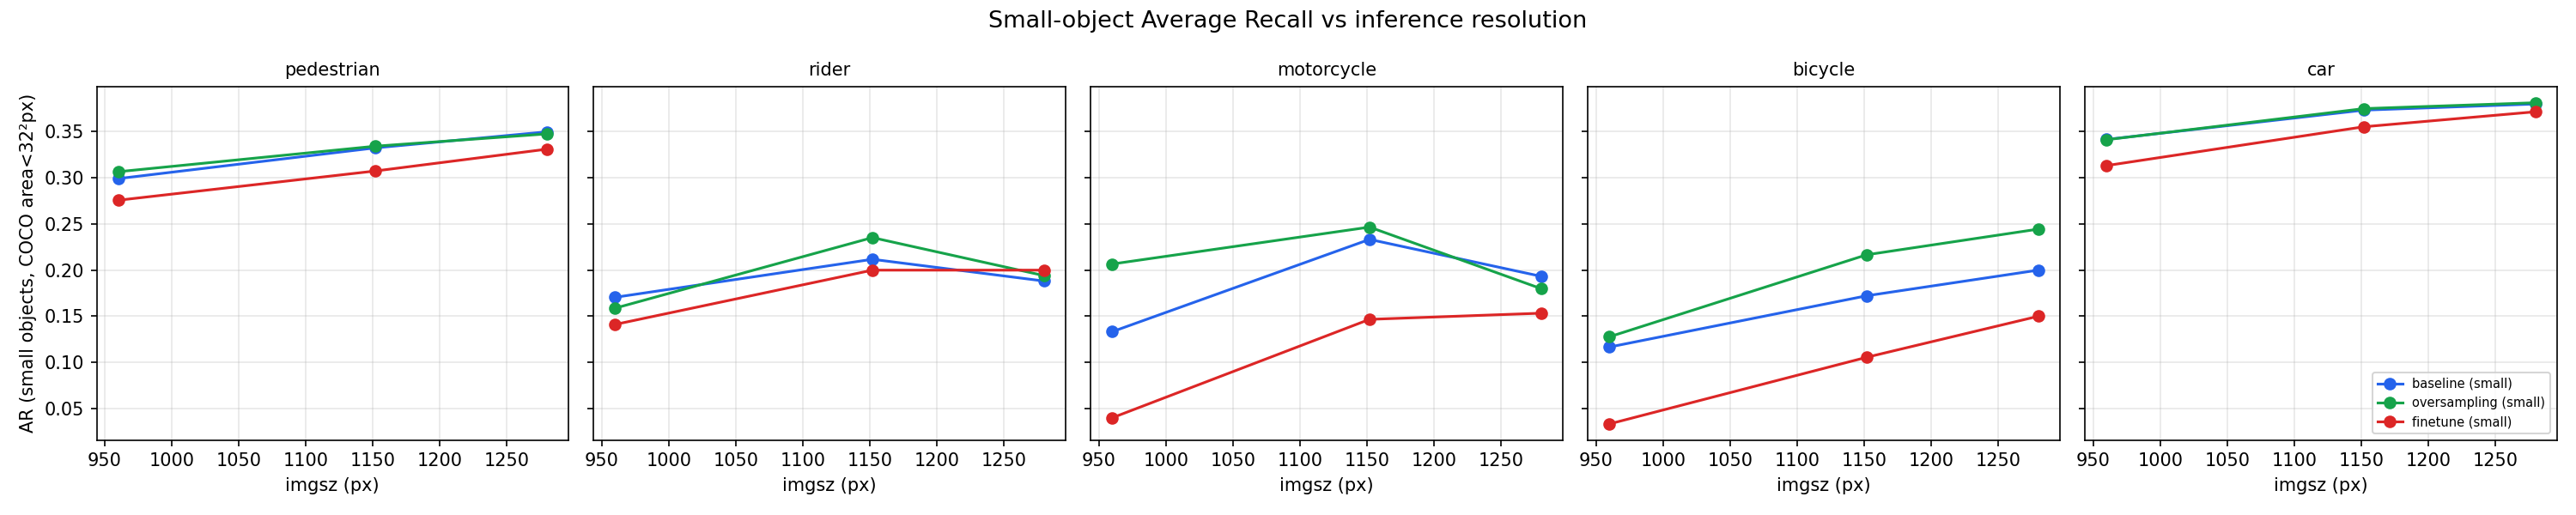

In [1]:
display(Image(filename=str(RA / 'charts' / 'ar_small_vs_imgsz_by_class.png')))

**rider** (n=17 small GT) and **motorcycle** (n=15 small GT) both peak sharply at
1152 then decline at 1280 -- the same inverted-U as the global metrics, now
localized specifically to small instances of these two classes. **bicycle**
(n=18) and **pedestrian**/**car** (n=495/3410) instead keep improving all the way
to 1280. Rider/motorcycle small-object counts are thin (15-17 instances) --
individual deltas should be read as indicative, not precise.

## 5. Visual comparison: Ground Truth vs predictions, same images, across resolutions

6 representative validation images (carried over from the earlier error-cause
analysis, so they're images already known to be diagnostically interesting:
small/distant VRUs, a large unoccluded rear-view motorcyclist, a large unoccluded
cyclist, and one dense small-object scene for breadth) were run through all 3
models x 3 resolutions. Each grid below has rows = model (baseline / oversampling
/ finetune, top to bottom) and columns = imgsz (960 / 1152 / 1280, left to right).
Green = ground truth, red = predictions (label + confidence).

### `c96e0b6a-f3d8aa78`
Large, unoccluded, confirmed-occluded=false rear-view motorcyclist (9.5% of frame).

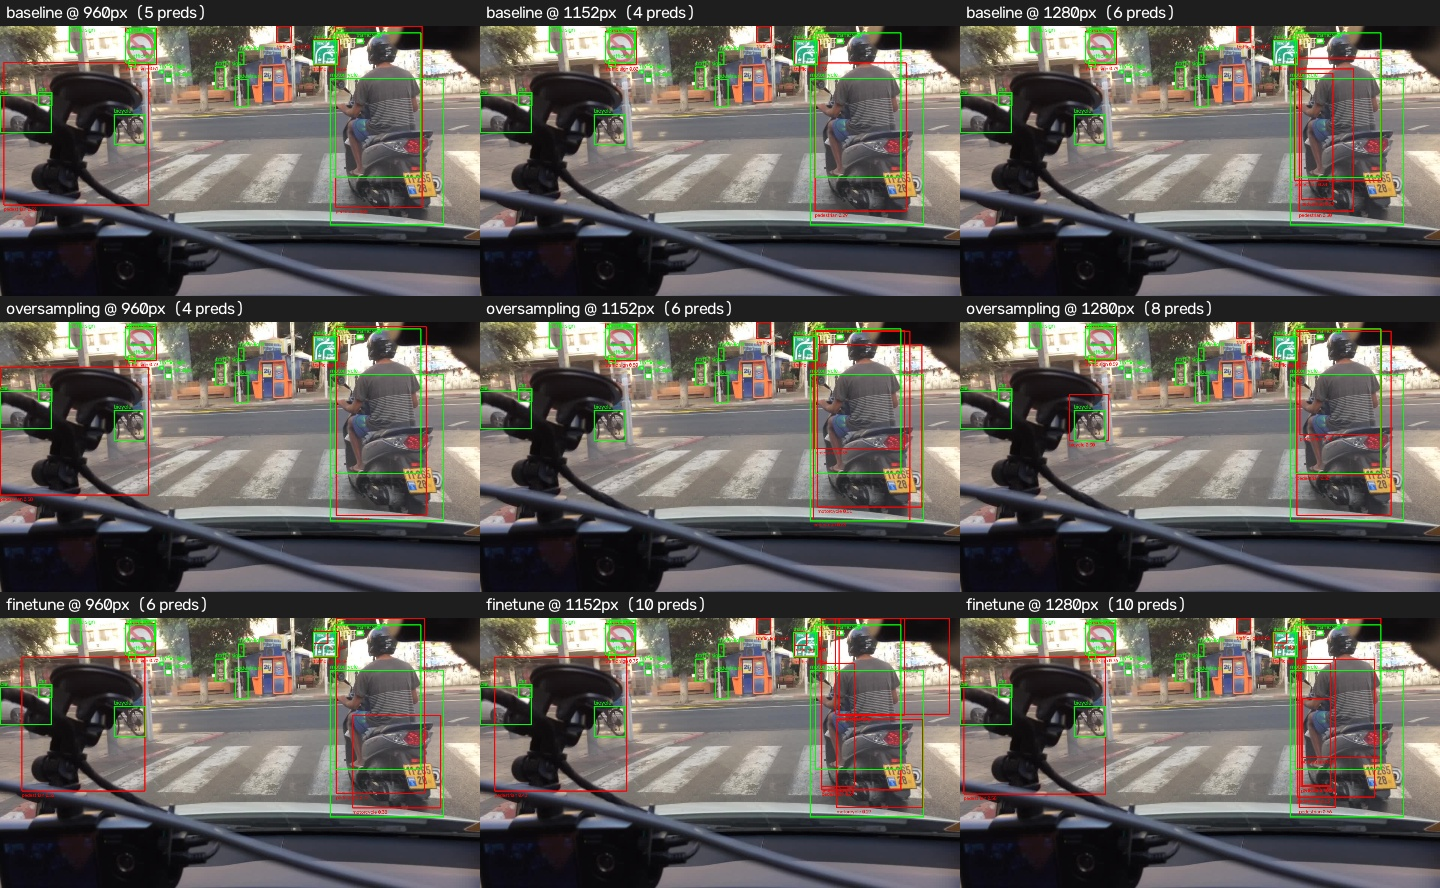

In [1]:
display(Image(filename=str(RA / 'visual_comparison' / 'c96e0b6a-f3d8aa78' / 'grid.jpg')))

### `4c1d2408-79034cda`
Large, unoccluded, clearly pedaling cyclist in daylight.

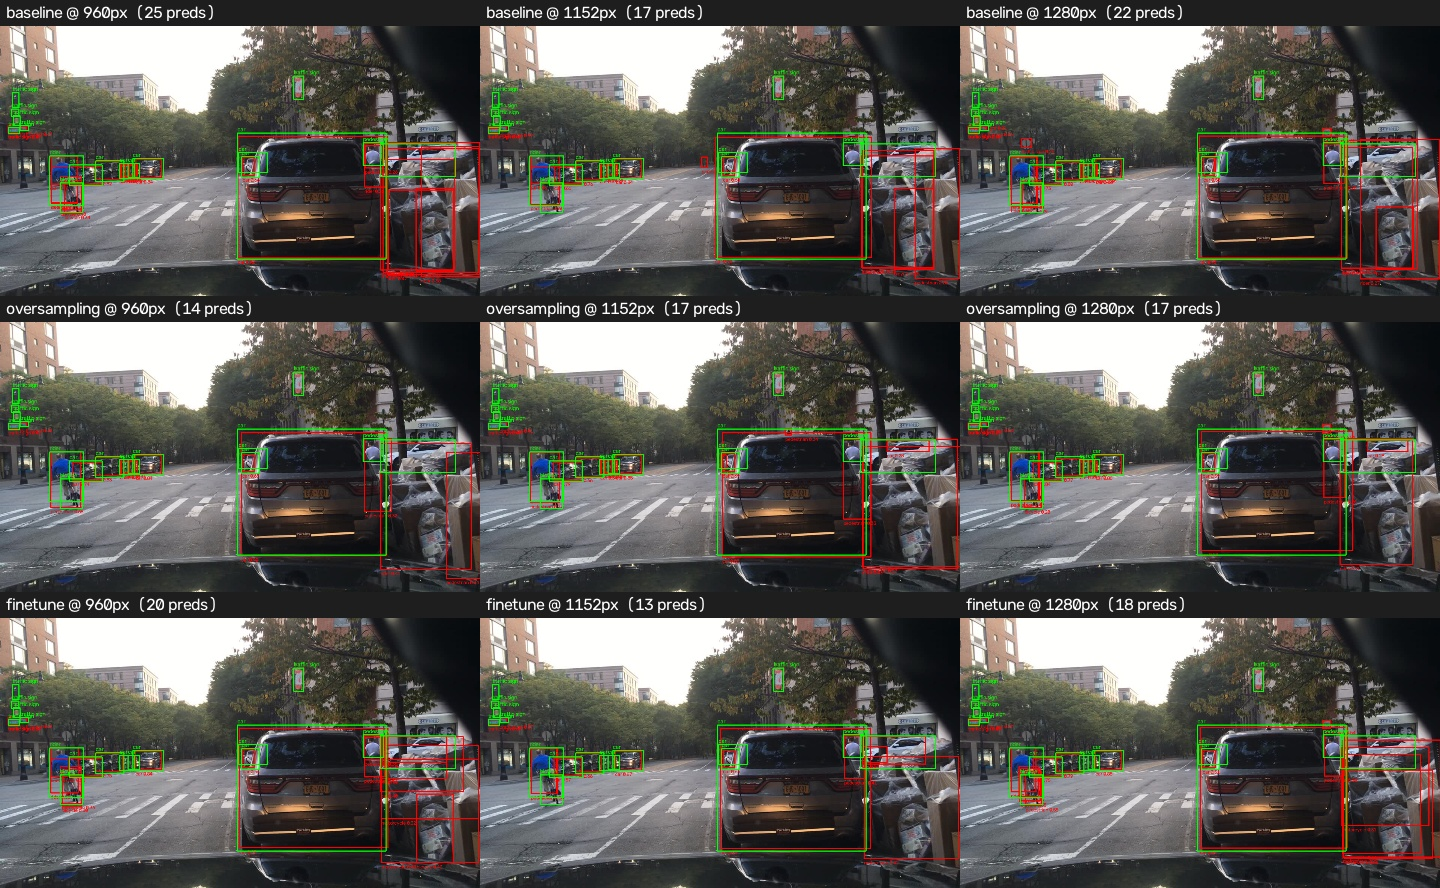

In [1]:
display(Image(filename=str(RA / 'visual_comparison' / '4c1d2408-79034cda' / 'grid.jpg')))

### `a48909f7-54e4bcff`
Crowded crosswalk; the GT 'rider' box here has no visible bicycle/motorcycle in frame (annotation-ambiguity case from the earlier error audit).

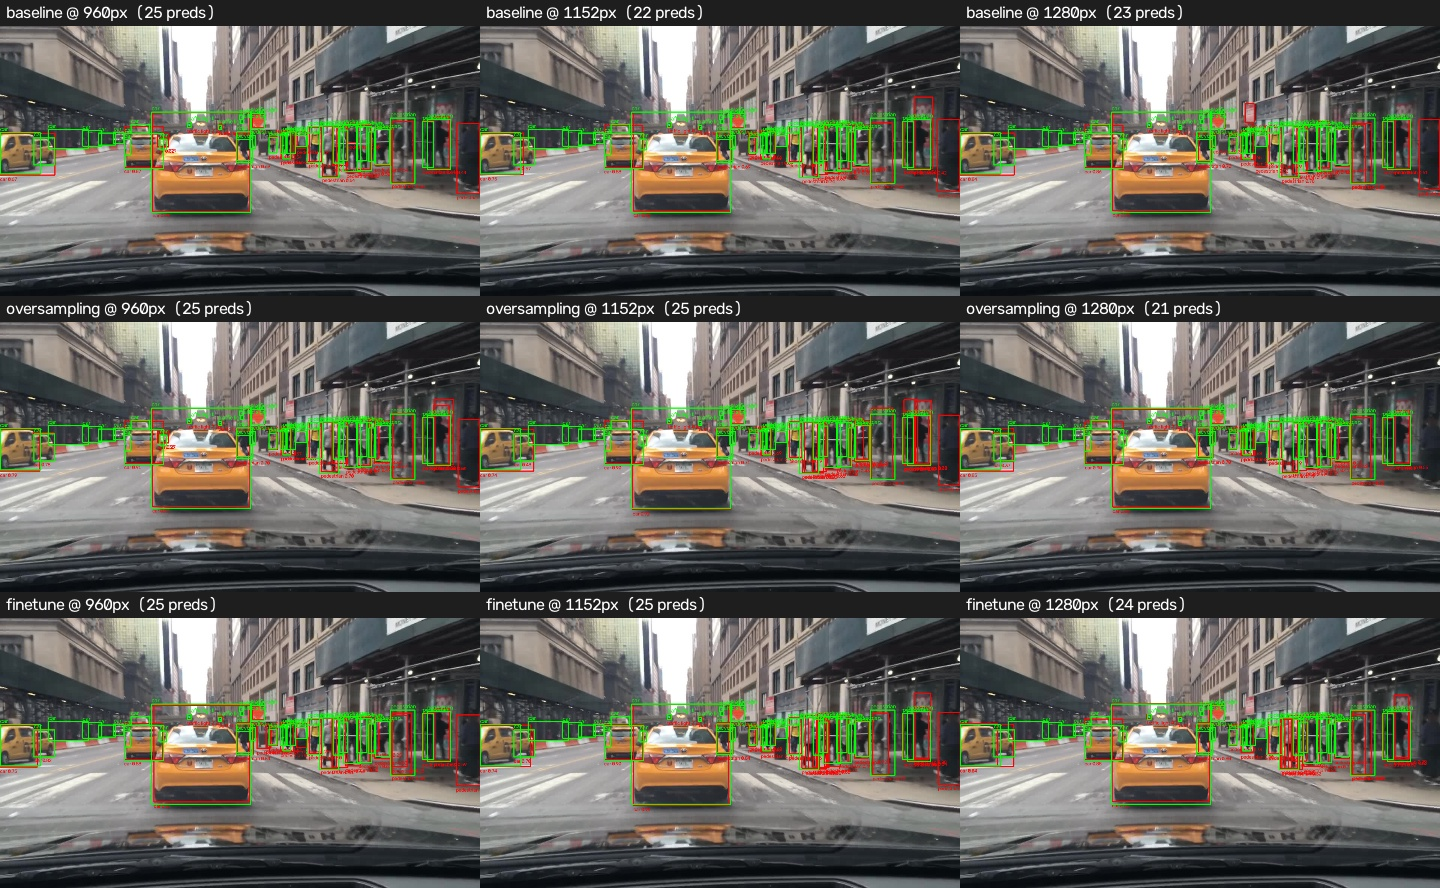

In [1]:
display(Image(filename=str(RA / 'visual_comparison' / 'a48909f7-54e4bcff' / 'grid.jpg')))

### Zoomed crops on the two most diagnostic objects

The full-frame grids above are too small to read predicted labels on these
specific small/borderline boxes, so `scripts/zoom_region_resolution_grid.py`
re-runs the same 9 (model, imgsz) combinations cropped tightly around each GT box.

**Cyclist** (`4c1d2408-79034cda`) -- GT box `[132, 346, 222, 479]`px:

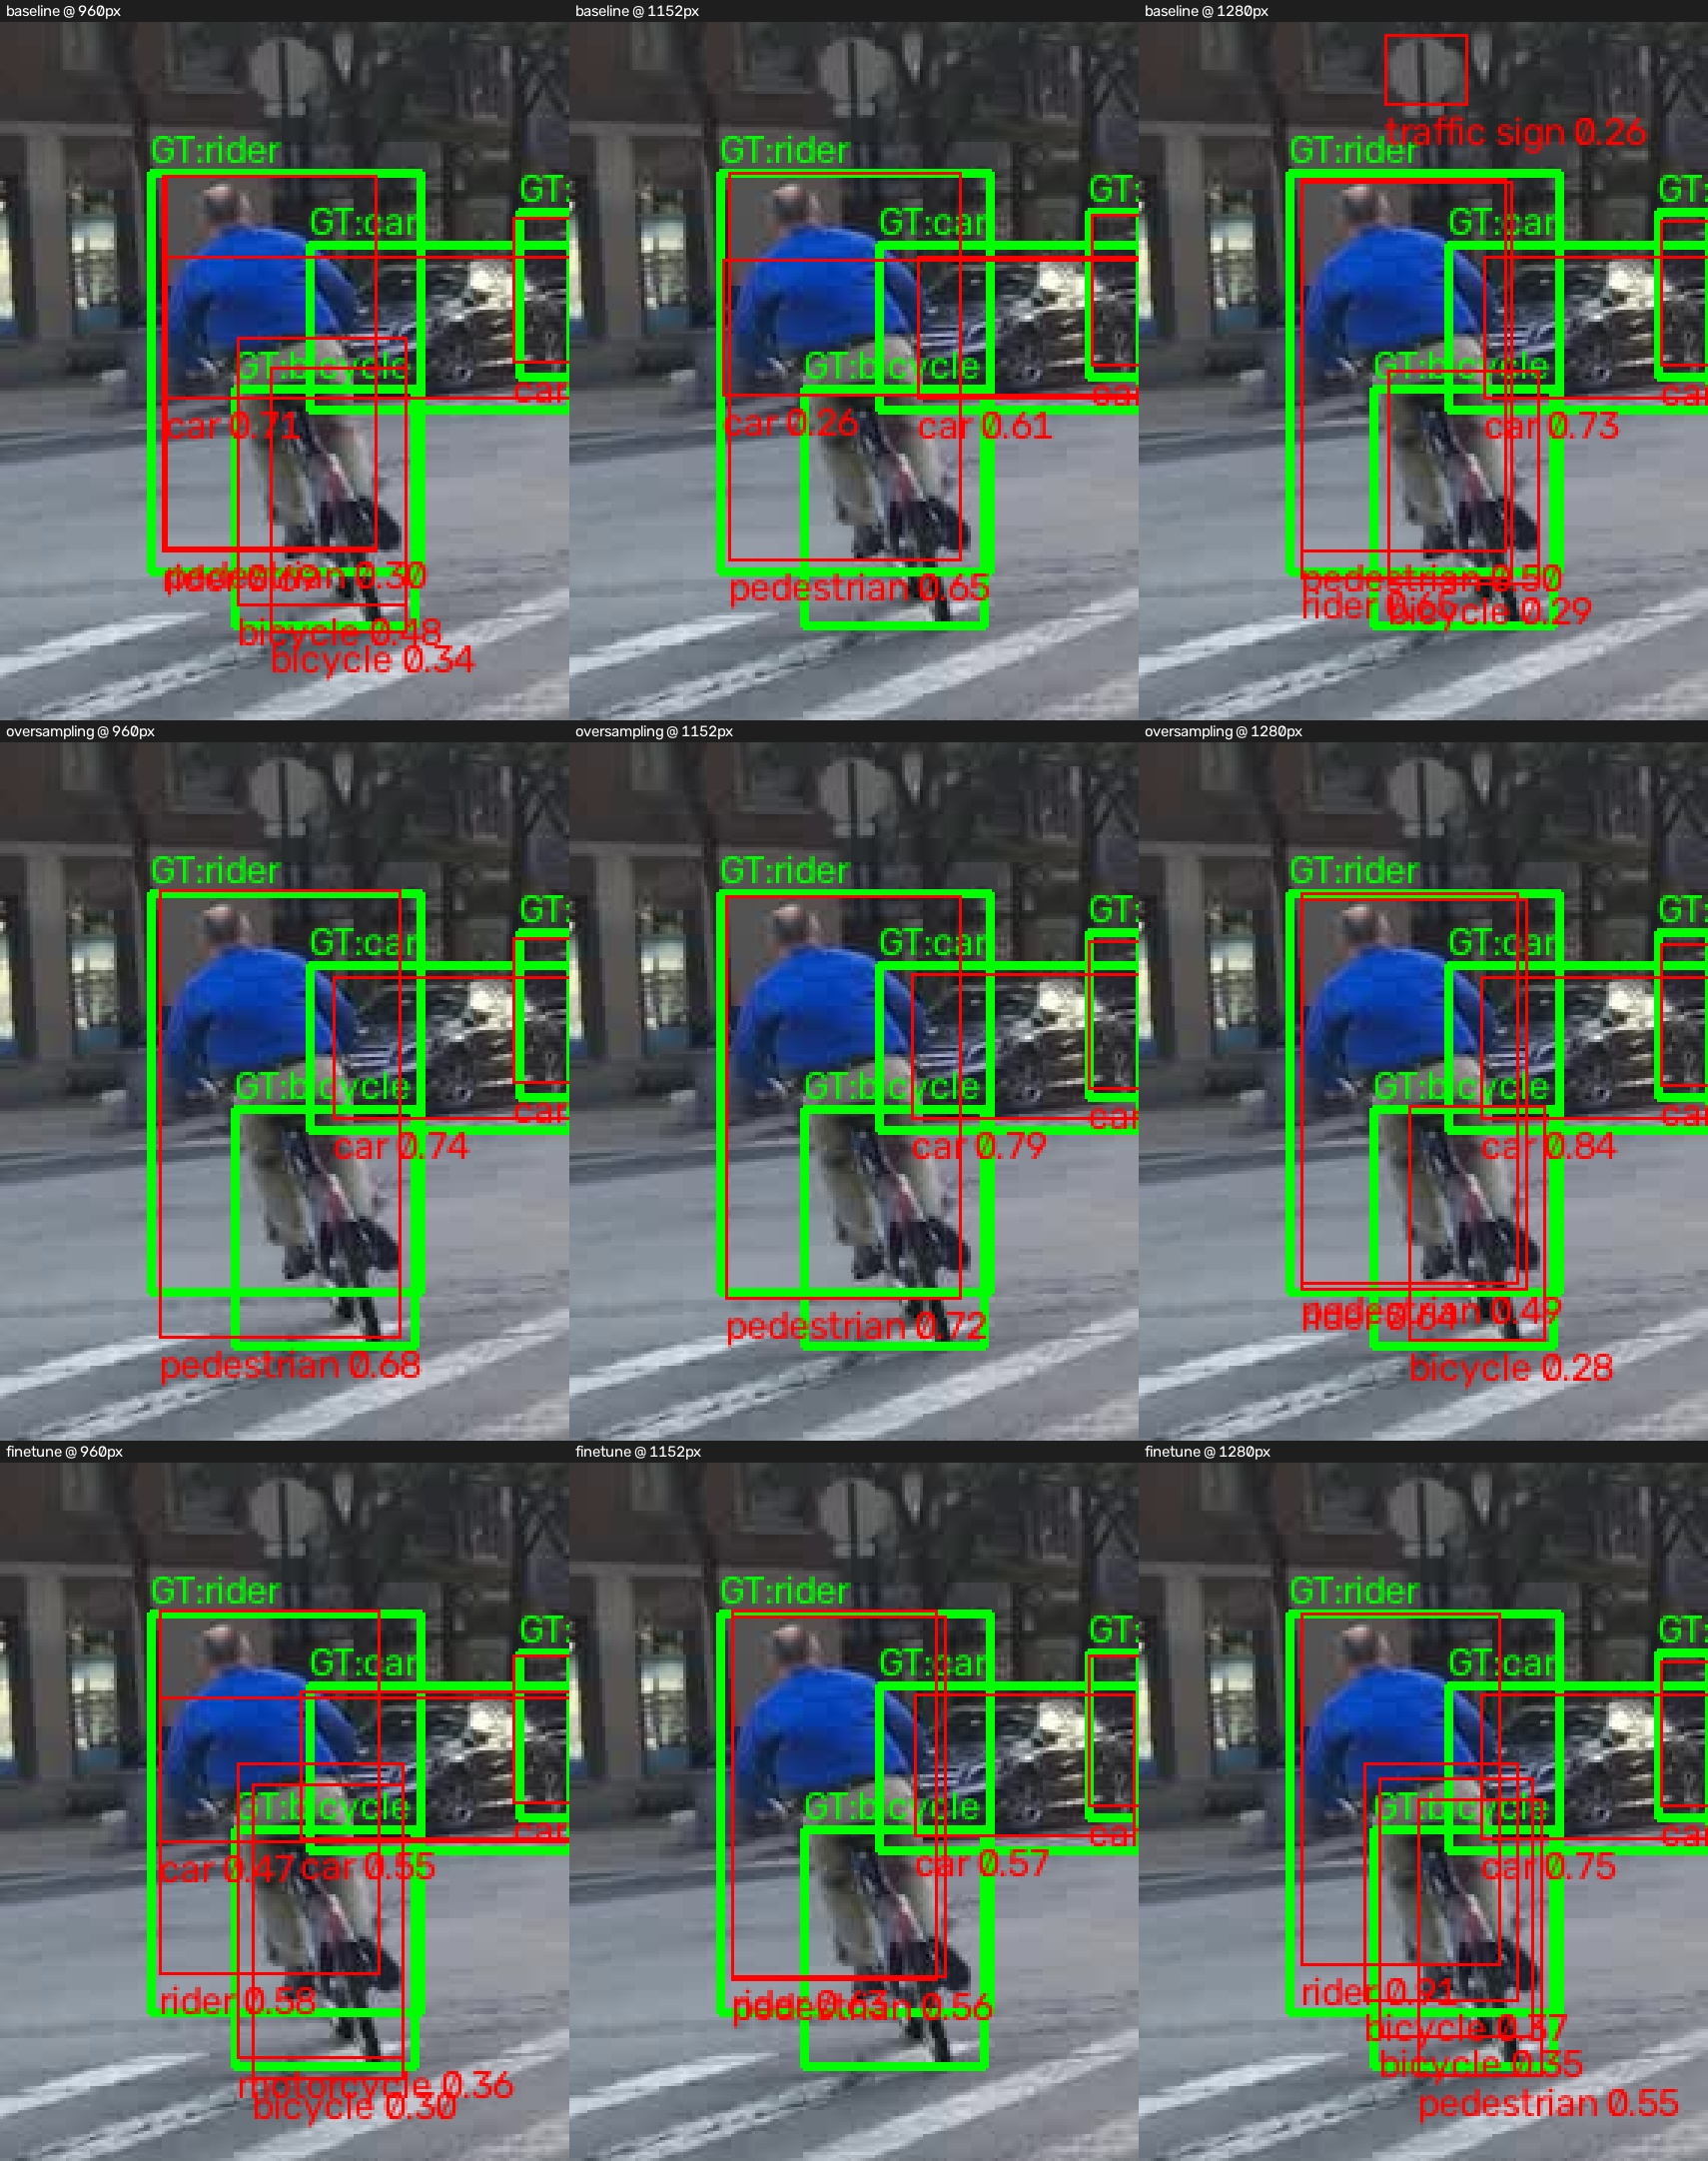

In [1]:
display(Image(filename=str(RA / 'visual_comparison' / '4c1d2408-79034cda' / 'zoom_grid.jpg')))

**Rear-view motorcyclist** (`c96e0b6a-f3d8aa78`) -- GT box `[894, 18, 1122, 403]`px:

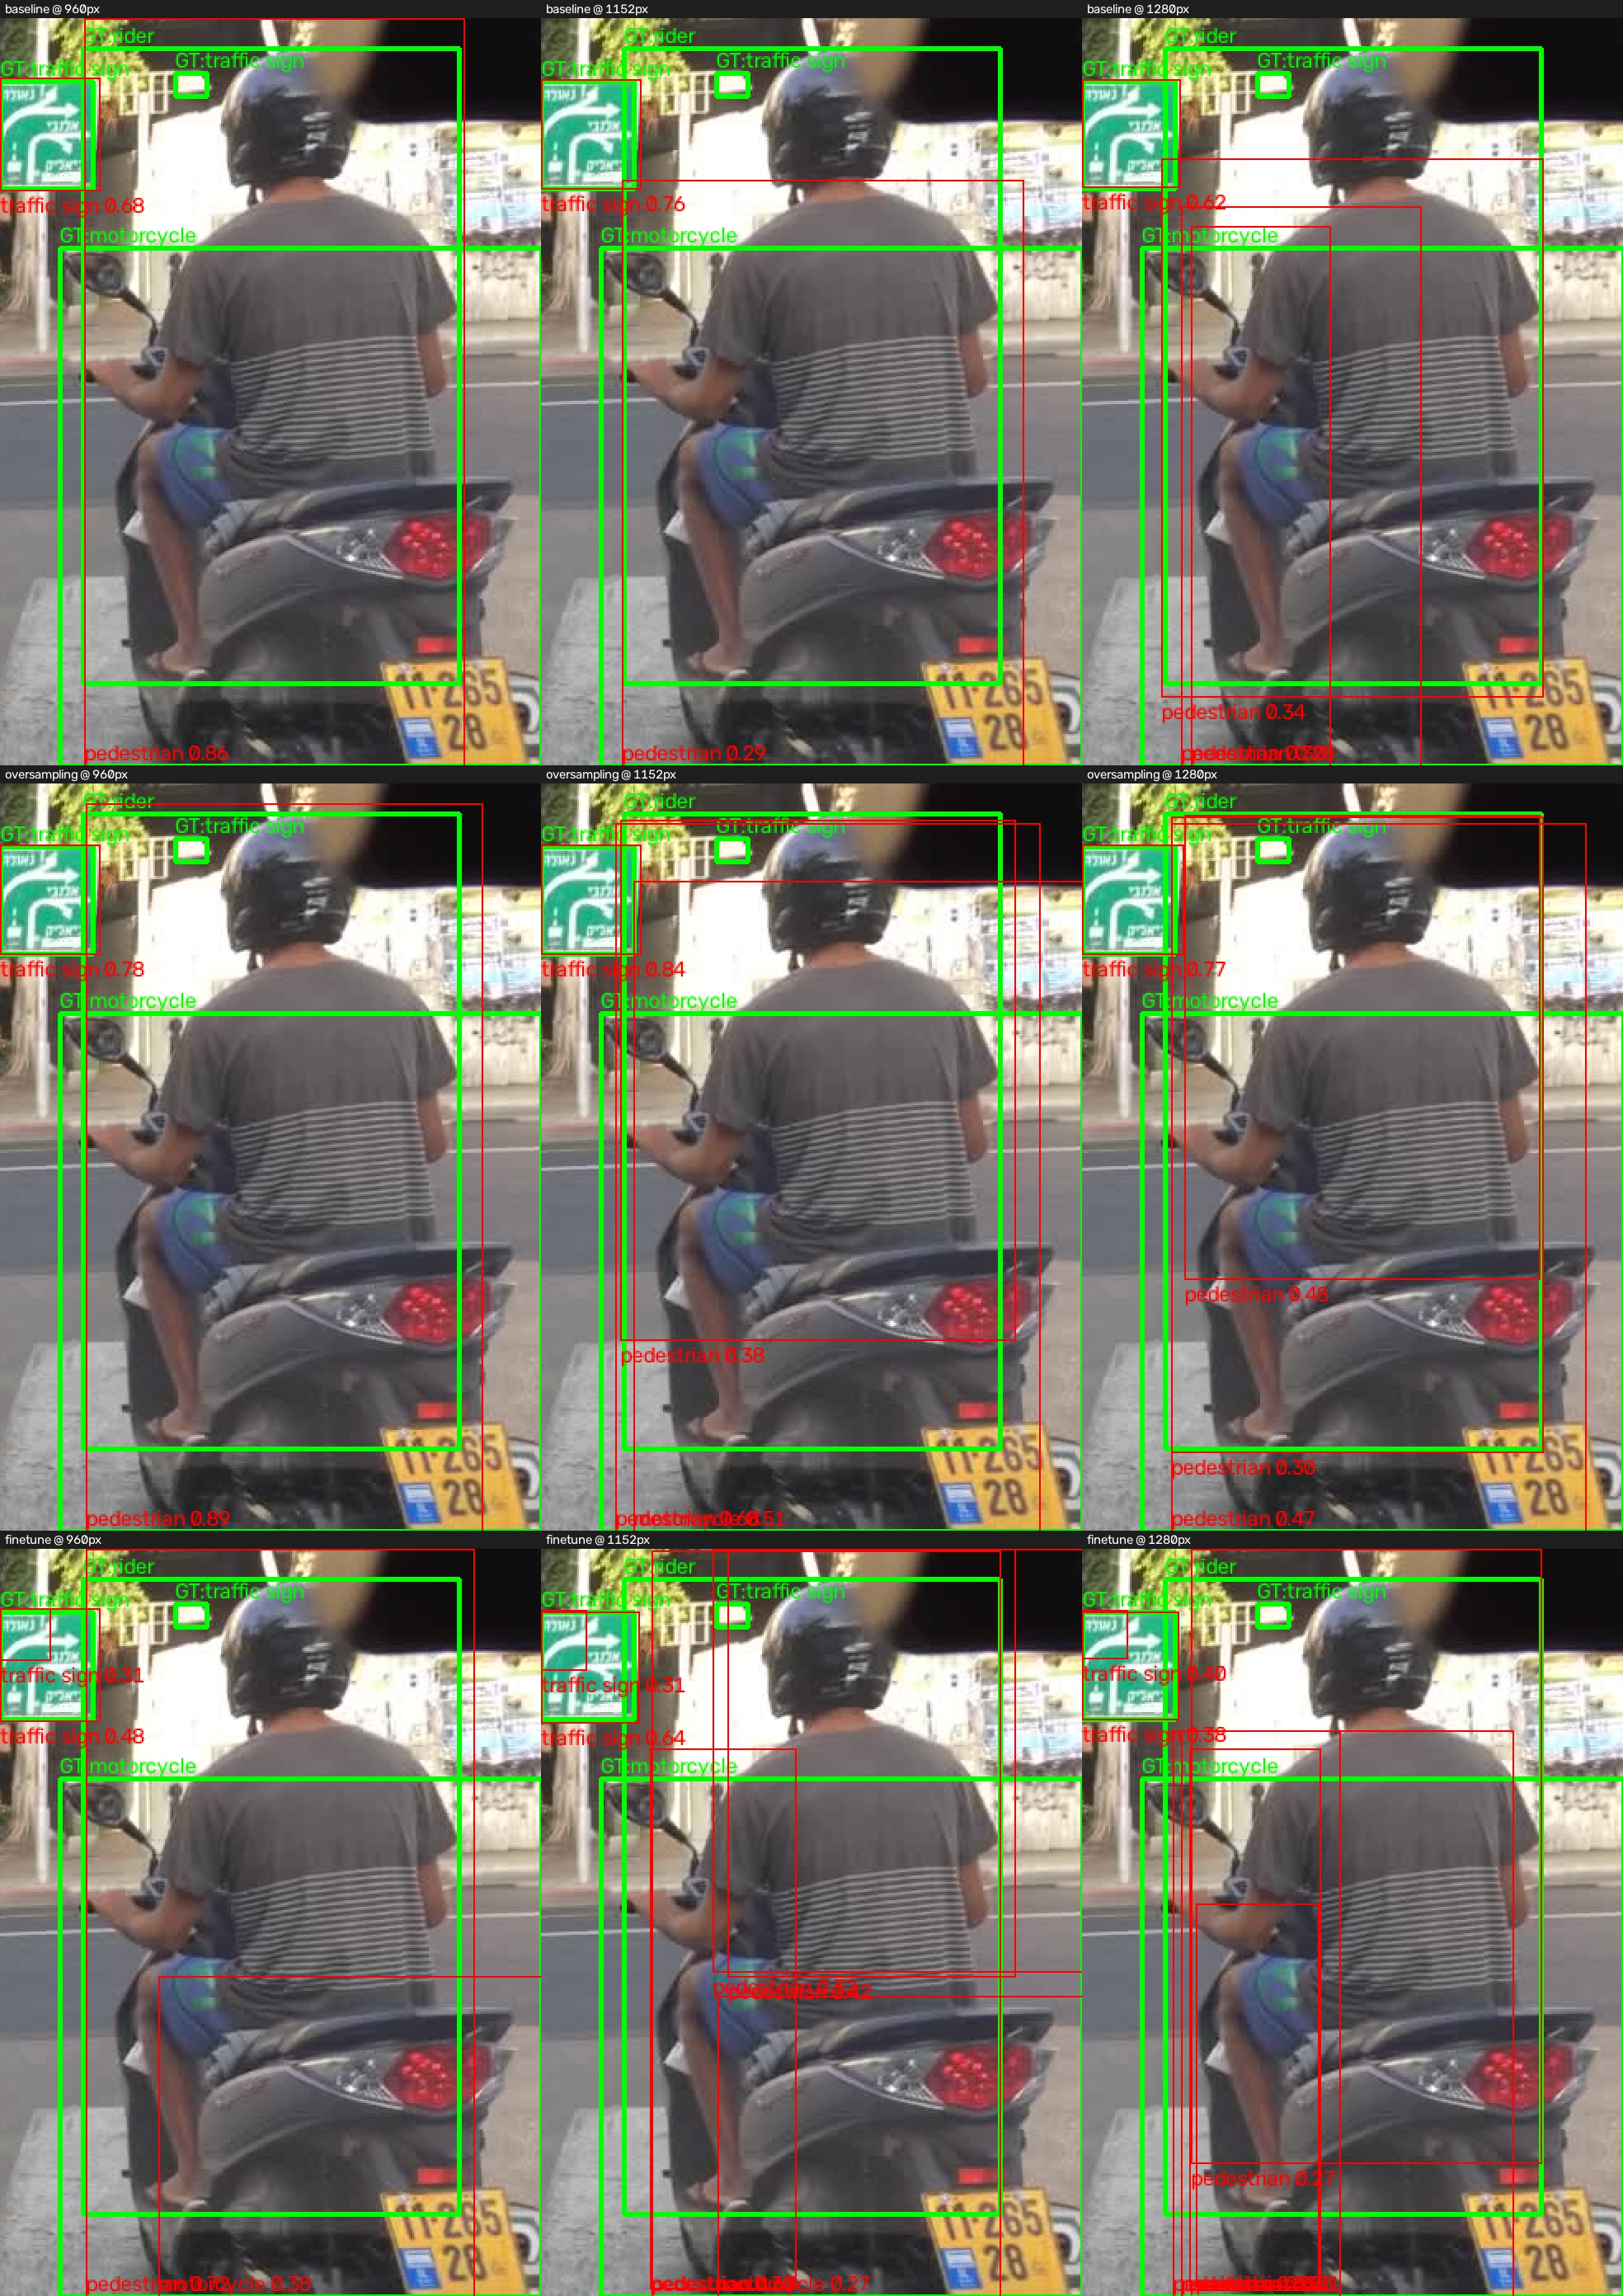

In [1]:
display(Image(filename=str(RA / 'visual_comparison' / 'c96e0b6a-f3d8aa78' / 'zoom_grid.jpg')))

**What these two cases actually show (read directly off the crops above, not
inferred):**

- **Rear-view motorcyclist**: at every resolution, on all three models, the
  top prediction on this box is still `pedestrian` -- resolution never flips this
  one to the correct class. What resolution *does* change is **confidence**, and
  it also starts fragmenting into multiple overlapping boxes at higher imgsz:
  baseline's `pedestrian` call drops from 0.86 (@960) to 0.29 (@1152) to 0.34
  (@1280, now with a second, harder-to-read overlapping box too); oversampling's
  drops from 0.89 (@960) to 0.38 (@1152) to 0.48 (@1280, now THREE overlapping
  `pedestrian` boxes at 0.48/0.30/0.47). At a realistic deployment threshold (e.g.
  conf>=0.5), the single wrong detection at 960 would mostly be filtered out at
  1152/1280 -- a real, practical precision benefit even without fixing the
  underlying classification error -- though the fragmentation into multiple
  lower-confidence boxes at 1280 is itself a new, minor side effect worth noting.
  Most plausible cause for the persistent misclassification (unchanged from the
  earlier error-cause analysis): from directly behind, the motorcycle body is
  largely hidden behind the rider's own torso/legs, so the discriminating visual
  cue is weak at any resolution -- this looks like a genuine representation
  limitation, not a small-object/resolution problem.
- **Cyclist**: messier -- every model produces several overlapping, competing
  boxes on this object rather than one clean call. `oversampling` predicts
  `pedestrian` as its highest-confidence box at all three resolutions (0.68 @960,
  0.72 @1152, 0.49 @1280) with no competing `rider`/`bicycle` call ever
  appearing. `baseline` and `finetune`, by contrast, do surface an explicit
  `rider` box among the overlapping predictions at some resolutions -- baseline
  @1280 (confidence not legible, overlapped by the `bicycle 0.29` label) and
  finetune clearly at @960 (`rider 0.58`) and @1280 (`rider 0.21`, alongside a
  confident `bicycle 0.87`). It doesn't always win against the competing
  `pedestrian`/`car` boxes, but it exists, which it does not for oversampling at
  any resolution tested here. This is a small, qualitative signal
  that oversampling's regression on this specific object is more persistent than
  baseline's original uncertainty, consistent with the earlier finding (P0 pass)
  that oversampling introduced this particular misclassification rather than
  fixing it.

## 6. CUDA OOM handling

Every (model, imgsz) run in `scripts/run_resolution_ablation.py` is wrapped in its
own `try/except`, catching `torch.cuda.OutOfMemoryError` and the generic
`RuntimeError('... out of memory ...')` case, recording `status="OOM"` in the
summary CSV, calling `torch.cuda.empty_cache()`, and continuing the sweep rather
than aborting. On this GPU (RTX 2050, 4GB) at batch=1, **no run hit this path** --
peak usage never exceeded ~147MB, so the safety net was not exercised this time,
but would prevent the whole ablation from being lost if a larger batch or a bigger
model were tested later.

## Conclusion

**Best resolution for these checkpoints, without retraining: 1152px.** It is the
peak (not just an improvement point) for mAP50/mAP50-95/precision on all three
models, and for AR_small on rider and motorcycle specifically -- and it is
effectively free: inference time is flat across 960/1152/1280 at batch=1 on this
hardware, and GPU memory headroom is not a constraint (147MB peak vs 4GB budget).
**1280px is not better** -- it overshoots and gives back part of the 1152 gain on
most metrics, most plausibly because these checkpoints were trained at a much
lower resolution (640/960) and 1280 strays furthest from that.

**Does it genuinely improve small-object / VRU detection?** Partially, and
genuinely -- but it is not a fix for everything the earlier error-cause analysis
found:
- **Yes, confirmed quantitatively**: small-object AR for rider (+4.1 to +7.6pt)
  and motorcycle (+4.0 to +10.0pt) both rise moving 960→1152, across both
  baseline and oversampling. Pedestrian/car/bicycle small-object AR improves too,
  continuing to rise even at 1280.
- **Yes, confirmed qualitatively, but narrowly**: on the large rear-view
  motorcyclist case, resolution sharply reduces the model's confidence in its
  wrong `pedestrian` call (0.86-0.89 @960 down to 0.29-0.46 @1152/1280) -- a real
  precision benefit at a sane deployment threshold, even without flipping the
  class.
- **No, resolution is not a complete fix**: the rear-view-motorcyclist
  misclassification itself persists at every resolution tested, for every model.
  Oversampling's specific cyclist regression (introduced, not fixed, by
  oversampling per the earlier P0 pass) also persists as the leading prediction
  at all three resolutions. These look like genuine representation/viewpoint
  limitations that resolution alone does not reach.

### Recommendation
1. **Adopt imgsz=1152 as the standard evaluation resolution going forward** -- it
   is a strictly better, free (no retraining, no extra latency on this hardware)
   choice than the 960px convention used in every prior round of this project.
2. This was an **inference-only** test -- the checkpoints are still trained at
   640/960px. The natural next experiment (not run here, since it requires
   retraining) is whether training at 1152px compounds this gain further, or
   whether the current checkpoints are already near the ceiling a *fixed* backbone
   can reach at higher input resolution.
3. Resolution does not substitute for the previously-recommended, still-untried
   P1 experiments (copy_paste/mixup ablation, `cls_pw` ablation) aimed at the
   resolution-independent classification failures surfaced here and in the
   earlier error-cause analysis -- both tracks are complementary, not
   alternatives.

## Reproducibility

All commands used to produce every artifact in this notebook are listed in
`reports/resolution_ablation/README.md`. This notebook itself was generated by
`scripts/build_resolution_ablation_notebook.py`, which reads the real CSV/PNG/JPG
files under `reports/resolution_ablation/` and embeds their actual content --
re-run that script after re-running the ablation to refresh this notebook.